In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [3]:
df = pd.read_csv("bank.csv")

X = df[["age", "balance"]].values
y = df["deposit"].map({"yes": 1, "no": 0}).values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

print("Форма train:", X_train_scaled.shape, "| test:", X_test_scaled.shape)
print("Доля класса 1 в train:", y_train.mean().round(4))
print("Пример масштабированных данных (первые 3 строки):")
print(np.round(X_train_scaled[:3], 2))

Форма train: (8929, 2) | test: (2233, 2)
Доля класса 1 в train: 0.4738
Пример масштабированных данных (первые 3 строки):
[[ 0.41 -0.32]
 [ 0.41  0.36]
 [-1.36 -0.45]]


In [4]:
svm_linear = SVC(kernel="linear", C=1.0, gamma="scale", random_state=42)
svm_linear.fit(X_train_scaled, y_train)
y_pred_lin = svm_linear.predict(X_test_scaled)
acc_lin = accuracy_score(y_test, y_pred_lin)

svm_rbf = SVC(kernel="rbf", C=1.0, gamma="scale", random_state=42)
svm_rbf.fit(X_train_scaled, y_train)
y_pred_rbf = svm_rbf.predict(X_test_scaled)
acc_rbf = accuracy_score(y_test, y_pred_rbf)

print(f"Linear SVM accuracy: {acc_lin*100:.2f}%")
print(f"RBF    SVM accuracy: {acc_rbf*100:.2f}%")
print("\n--- Classification report (RBF) ---")
print(classification_report(y_test, y_pred_rbf, digits=3))
print("Confusion matrix (RBF):\n", confusion_matrix(y_test, y_pred_rbf))

Linear SVM accuracy: 52.89%
RBF    SVM accuracy: 60.05%

--- Classification report (RBF) ---
              precision    recall  f1-score   support

           0      0.592     0.773     0.671      1175
           1      0.619     0.409     0.493      1058

    accuracy                          0.601      2233
   macro avg      0.605     0.591     0.582      2233
weighted avg      0.605     0.601     0.586      2233

Confusion matrix (RBF):
 [[908 267]
 [625 433]]


In [5]:
n_train = len(X_train_scaled)
n_sv    = len(svm_rbf.support_vectors_)
share   = n_sv / n_train * 100

print(f"Опорных векторов (RBF): {n_sv} из {n_train} ({share:.1f}% обучающей выборки)")
print("По классам [0, 1]:", svm_rbf.n_support_)
print("Индексы SV в train (первые 10):", svm_rbf.support_[:10])

Опорных векторов (RBF): 7415 из 8929 (83.0% обучающей выборки)
По классам [0, 1]: [3700 3715]
Индексы SV в train (первые 10): [ 6  8 10 12 13 14 15 18 19 21]


In [6]:
svm_linear_c = SVC(kernel="linear", C=0.01, gamma="scale", random_state=42)
svm_linear_c.fit(X_train_scaled, y_train)
y_pred_lin_c = svm_linear_c.predict(X_test_scaled)
acc_lin_c = accuracy_score(y_test, y_pred_lin)
svm_linear_C = SVC(kernel="linear", C=1000, gamma="scale", random_state=42)
svm_linear_C.fit(X_train_scaled, y_train)
y_pred_lin_C = svm_linear_C.predict(X_test_scaled)
acc_lin_C = accuracy_score(y_test, y_pred_lin)
print(f"Linear SVM accuracy c: {acc_lin_c*100:.2f}%")

print(f"Linear SVM accuracy: {acc_lin*100:.2f}%")

print(f"Linear SVM accuracy C: {acc_lin_C*100:.2f}%")


Linear SVM accuracy c: 52.89%
Linear SVM accuracy: 52.89%
Linear SVM accuracy C: 52.89%


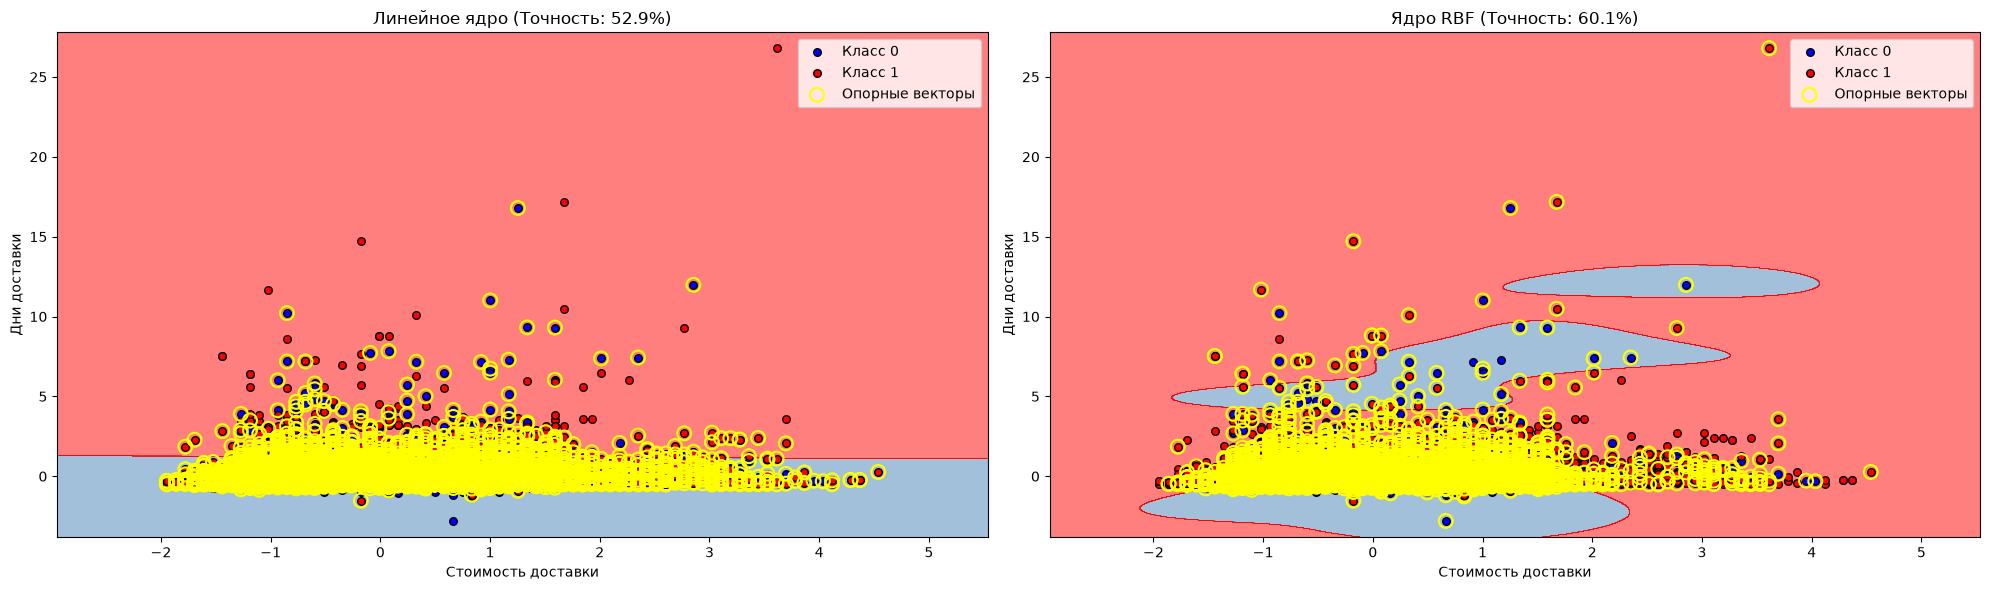

In [7]:
def plot_decision_boundary(model, ax, title):
    X_set, y_set = X_train_scaled, y_train
    X1, X2 = np.meshgrid(
        np.arange(
            start=X_set[:, 0].min() - 1, stop=X_set[:, 0].max() + 1, step=0.01
        ),
        np.arange(
            start=X_set[:, 1].min() - 1, stop=X_set[:, 1].max() + 1, step=0.01
        ),
    )
    ax.contourf(
        X1,
        X2,
        model.predict(np.array([X1.ravel(), X2.ravel()]).T).reshape(X1.shape),
        alpha=0.5,
        cmap=ListedColormap(("steelblue", "red")),
    )
    
    for i, j in enumerate(np.unique(y_set)):
        ax.scatter(
            X_set[y_set == j, 0],
            X_set[y_set == j, 1],
            color=ListedColormap(("blue", "red"))(i),
            label=f"Класс {j}",
            edgecolors="k",
            s=30,
        )
        
    ax.scatter(
        model.support_vectors_[:, 0],
        model.support_vectors_[:, 1],
        facecolors="none",
        edgecolors="yellow",
        s=100,
        linewidth=1.5,
        label="Опорные векторы",
    )
    
    ax.set_title(title)
    ax.set_xlabel("Стоимость доставки")
    ax.set_ylabel("Дни доставки")
    ax.legend()

fig, axes = plt.subplots(1, 2, figsize=(20, 6))

plot_decision_boundary(
    svm_linear, axes[0], f"Линейное ядро (Точность: {acc_lin*100:.1f}%)"
)
plot_decision_boundary(svm_rbf, axes[1], f"Ядро RBF (Точность: {acc_rbf*100:.1f}%)")

plt.tight_layout()
plt.show()